In [2]:
from datasets import load_dataset

ds = load_dataset("mteb/banking77")
print(ds)

train_df = ds["train"].to_pandas()
test_df = ds["test"].to_pandas()

# build the label list from the data
label_map = (train_df[["label", "label_text"]].drop_duplicates()
             .sort_values("label"))
label_names = label_map["label_text"].tolist()
print(len(label_names), "classes")

train_df["label_name"] = train_df["label"].apply(lambda i: label_names[i])
train_df.sample(5, random_state=1)

README.md:   0%|          | 0.00/16.6k [00:00<?, ?B/s]

c:\Users\USER\Desktop\AI_ML_Projects\banking-intent-classifier\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\USER\.cache\huggingface\hub\datasets--mteb--banking77. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\USER\Desktop\AI_ML_Projects\banking-intent-classifier\.venv\Lib\site-packag

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 91.4kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/9993 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3076 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 9993
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 3076
    })
})
77 classes


,text,label,label_text,label_name
1814,What is the reason when I tried to pay contact...,23,contactless_not_working,contactless_not_working
881,Do you allow currency exchanges?,36,fiat_currency_support,fiat_currency_support
1122,Does the auto top-up have any limits?,4,automatic_top_up,automatic_top_up
6807,My card payment's cancelled,53,reverted_card_payment?,reverted_card_payment?
2911,Which currencies do you handle?,54,supported_cards_and_currencies,supported_cards_and_currencies


In [3]:
label_names = [name.replace("?", "") for name in label_names]
train_df["label_name"] = train_df["label"].apply(lambda i: label_names[i])
test_df["label_name"] = test_df["label"].apply(lambda i: label_names[i])
train_df[["text", "label", "label_name"]].head()

,text,label,label_name
0,I am still waiting on my card?,11,card_arrival
1,What can I do if my card still hasn't arrived ...,11,card_arrival
2,I have been waiting over a week. Is the card s...,11,card_arrival
3,Can I track my card while it is in the process...,11,card_arrival
4,"How do I know if I will get my card, or if it ...",11,card_arrival


count     77.000000
mean     129.779221
std       32.974321
min       35.000000
25%      111.000000
50%      127.000000
75%      158.000000
max      187.000000
Name: count, dtype: float64


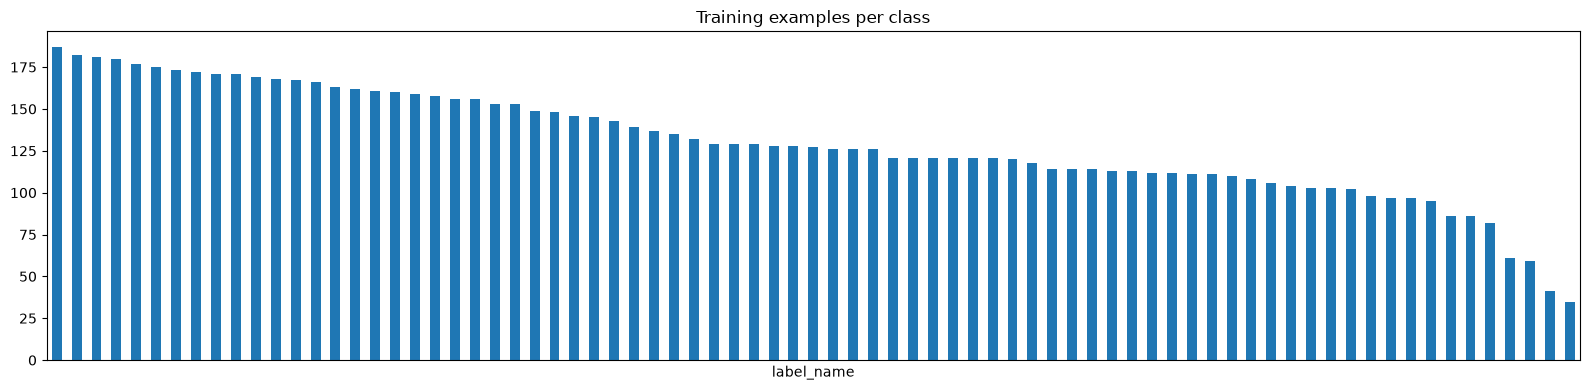

In [4]:
import matplotlib.pyplot as plt

counts = train_df["label_name"].value_counts()
print(counts.describe())

counts.plot(kind="bar", figsize=(16, 4))
plt.title("Training examples per class")
plt.xticks([])   # 77 labels won't fit, so hide them
plt.tight_layout()
plt.show()

In [5]:
train_df["n_words"] = train_df["text"].str.split().str.len()
train_df["n_words"].describe()

count    9993.000000
mean       11.955369
std         7.891187
min         3.000000
25%         7.000000
50%        10.000000
75%        13.000000
max        79.000000
Name: n_words, dtype: float64

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

baseline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=1000, C=10)),
])

baseline.fit(train_df["text"], train_df["label"])
preds = baseline.predict(test_df["text"])

acc = accuracy_score(test_df["label"], preds)
f1 = f1_score(test_df["label"], preds, average="macro")
print(f"Accuracy: {acc:.4f} | Macro-F1: {f1:.4f}")

Accuracy: 0.8937 | Macro-F1: 0.8939


In [7]:
import pandas as pd

report = classification_report(
    test_df["label"], preds, target_names=label_names, output_dict=True
)
worst = (pd.DataFrame(report).T.iloc[:77]
         .sort_values("f1-score").head(10))
worst[["precision", "recall", "f1-score"]]

,precision,recall,f1-score
balance_not_updated_after_bank_transfer,0.645833,0.775000,0.704545
top_up_failed,0.756098,0.775000,0.765432
pending_transfer,0.823529,0.717949,0.767123
card_not_working,0.660714,0.925000,0.770833
wrong_exchange_rate_for_cash_withdrawal,0.810811,0.750000,0.779221
card_payment_not_recognised,0.878788,0.725000,0.794521
verify_my_identity,0.815789,0.775000,0.794872
transfer_not_received_by_recipient,0.750000,0.846154,0.795181
topping_up_by_card,0.882353,0.750000,0.810811
top_up_reverted,0.804878,0.825000,0.814815
